<a href="https://colab.research.google.com/github/aymanbmr/KNN-Project/blob/main/breastcancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.datasets import load_breast_cancer
import pandas as pd
import numpy as np

data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

print(df.shape)
print(df.head())

(569, 31)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0   

In [ ]:
print(data.target_names)
print(df['target'].value_counts())

['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64


In [ ]:
df.describe().T[['min', 'max', 'mean']]

,min,max,mean
mean radius,6.981000,28.11000,14.127292
mean texture,9.710000,39.28000,19.289649
mean perimeter,43.790000,188.50000,91.969033
mean area,143.500000,2501.00000,654.889104
mean smoothness,0.052630,0.16340,0.096360
mean compactness,0.019380,0.34540,0.104341
mean concavity,0.000000,0.42680,0.088799
mean concave points,0.000000,0.20120,0.048919
mean symmetry,0.106000,0.30400,0.181162
mean fractal dimension,0.049960,0.09744,0.062798


In [ ]:
from sklearn.model_selection import train_test_split
X = df.drop('target', axis=1).values
y= df['target'].values
X_train ,X_test, y_train, y_test= train_test_split (X, y , test_size=0.2, random_state=42)

In [ ]:
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


In [ ]:
def euclidean_distance(a,b):
  difference = a - b
  squared=difference ** 2
  total = np.sum(squared)
  distance=np.sqrt(total)
  return distance

In [ ]:
print(euclidean_distance(X_train[0], X_train[1]))
print(euclidean_distance(X_train[0], X_train[0]))

2064.3326118117475
0.0


In [ ]:
new_patient=X_test[0]
distances= []
for patient in X_train:
  d=euclidean_distance(new_patient, patient)
  distances.append(d)
distances=np.array(distances)
print("number of distances:",len(distances))
k=5
nearest_indexes= np.argsort(distances)[:k]
print("indexes of the 5 nearest:",nearest_indexes)
print("their distances",distances[nearest_indexes])
nearest_labels = y_train[nearest_indexes]
print("theri labels",nearest_labels)

prediction=np.bincount(nearest_labels).argmax()
print("prediction:",prediction)
print("real answer:",y_test[0])

number of distances: 455
indexes of the 5 nearest: [326 354 147 340 156]
their distances [13.23427258 37.46529809 37.65164384 45.20300917 46.0377704 ]
theri labels [1 0 0 1 1]
prediction: 1
real answer: 1


In [ ]:
class MyKNN:
  def __init__(self,k=5):
    self.k=k
  def fit(self,X,y):
    self.X_train= X
    self.y_train= y
  def predict_one(self,new_patient):
    distances=[]
    for patient in self.X_train:
      d=euclidean_distance(new_patient,patient)
      distances.append(d)
    distances=np.array(distances)
    nearest_indexes=np.argsort(distances)[:self.k]
    nearest_labels=self.y_train[nearest_indexes]
    return np.bincount(nearest_labels).argmax()
  def predict (self, X):
    predictions=[]
    for patient in X:
      predictions.append(self.predict_one(patient))
    return np.array(predictions)

In [ ]:
model = MyKNN(k=5)
model.fit(X_train,y_train)
predictions=model.predict(X_test)
print("first 10 predictions:",predictions[:10])
print("fisrt 10 real labels:",y_test[:10])
accuracy=np.mean(predictions==y_test)
print("accuracy:",accuracy)

first 10 predictions: [1 0 0 1 1 0 0 0 1 1]
fisrt 10 real labels: [1 0 0 1 1 0 0 0 1 1]
accuracy: 0.956140350877193


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

sk_model = KNeighborsClassifier(n_neighbors=5)
sk_model.fit(X_train, y_train)

sk_predictions = sk_model.predict(X_test)
sk_accuracy = np.mean(sk_predictions == y_test)

print("My KNN accuracy:     ", accuracy)
print("sklearn KNN accuracy:", sk_accuracy)
print("Same predictions?    ", np.array_equal(predictions, sk_predictions))

My KNN accuracy:      0.956140350877193
sklearn KNN accuracy: 0.956140350877193
Same predictions?     True


In [ ]:
ranges = X_train.max(axis=0) - X_train.min(axis=0)
for name, r in zip(data.feature_names, ranges):
    print(f"{name:25s} {r:10.3f}")

mean radius                   20.419
mean texture                  29.570
mean perimeter               140.580
mean area                   2330.600
mean smoothness                0.111
mean compactness               0.292
mean concavity                 0.427
mean concave points            0.201
mean symmetry                  0.187
mean fractal dimension         0.047
radius error                   2.762
texture error                  4.525
perimeter error               21.223
area error                   535.398
smoothness error               0.029
compactness error              0.133
concavity error                0.396
concave points error           0.053
symmetry error                 0.054
fractal dimension error        0.029
worst radius                  27.362
worst texture                 37.520
worst perimeter              196.710
worst area                  4030.400
worst smoothness               0.147
worst compactness              0.911
worst concavity                1.252
w

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Before:", X_train[0][:4])
print("After: ", np.round(X_train_scaled[0][:4], 2))

Before: [  9.029  17.33   58.79  250.5  ]
After:  [-1.44 -0.44 -1.36 -1.14]


In [ ]:
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)
acc_raw = knn_raw.score(X_test, y_test)

knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(X_train_scaled, y_train)
acc_scaled = knn_scaled.score(X_test_scaled, y_test)

print("Accuracy WITHOUT scaling:", round(acc_raw, 4))
print("Accuracy WITH scaling:   ", round(acc_scaled, 4))

Accuracy WITHOUT scaling: 0.9561
Accuracy WITH scaling:    0.9474


In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

model_raw = KNeighborsClassifier(n_neighbors=5)
model_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

scores_raw = cross_val_score(model_raw, X, y, cv=10)
scores_scaled = cross_val_score(model_scaled, X, y, cv=10)

print("WITHOUT scaling:", round(scores_raw.mean(), 4))
print("WITH scaling:   ", round(scores_scaled.mean(), 4))

WITHOUT scaling: 0.9298
WITH scaling:    0.9666


In [ ]:
## Part 4 – Choosing k

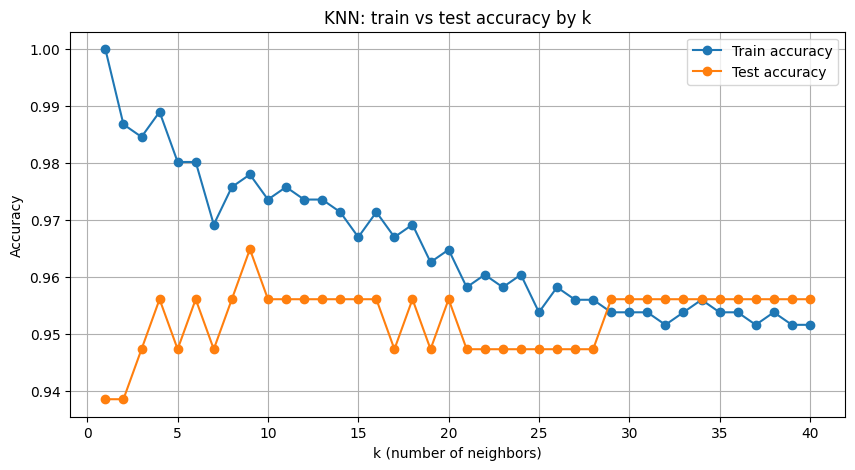

In [ ]:
import matplotlib.pyplot as plt

k_values = range(1, 41)
train_scores = []
test_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    train_scores.append(knn.score(X_train_scaled, y_train))
    test_scores.append(knn.score(X_test_scaled, y_test))

plt.figure(figsize=(10, 5))
plt.plot(k_values, train_scores, label="Train accuracy", marker="o")
plt.plot(k_values, test_scores, label="Test accuracy", marker="o")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Accuracy")
plt.title("KNN: train vs test accuracy by k")
plt.legend()
plt.grid(True)
plt.show()

Best k: 5
Best accuracy: 0.9666


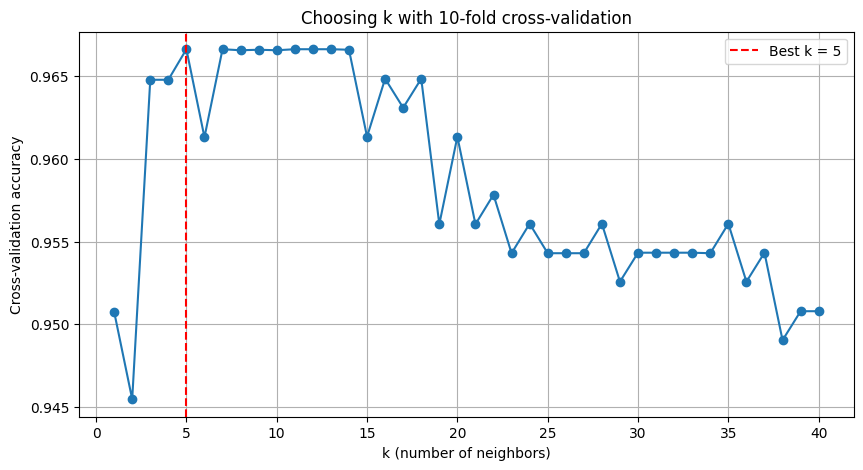

In [ ]:
cv_scores = []

for k in k_values:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(model, X, y, cv=10)
    cv_scores.append(scores.mean())

best_k = k_values[np.argmax(cv_scores)]
print("Best k:", best_k)
print("Best accuracy:", round(max(cv_scores), 4))

plt.figure(figsize=(10, 5))
plt.plot(k_values, cv_scores, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"Best k = {best_k}")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Cross-validation accuracy")
plt.title("Choosing k with 10-fold cross-validation")
plt.legend()
plt.grid(True)
plt.show()

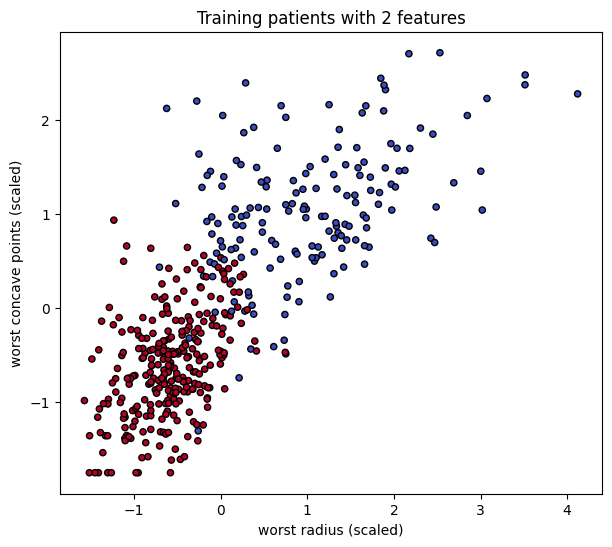

In [ ]:
feature_names = list(data.feature_names)
f1, f2 = "worst radius", "worst concave points"
i1 = feature_names.index(f1)
i2 = feature_names.index(f2)

X2_train = X_train[:, [i1, i2]]

scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)

plt.figure(figsize=(7, 6))
plt.scatter(X2_train_scaled[:, 0], X2_train_scaled[:, 1],
            c=y_train, cmap="coolwarm", edgecolor="k", s=20)
plt.xlabel(f1 + " (scaled)")
plt.ylabel(f2 + " (scaled)")
plt.title("Training patients with 2 features")
plt.show()

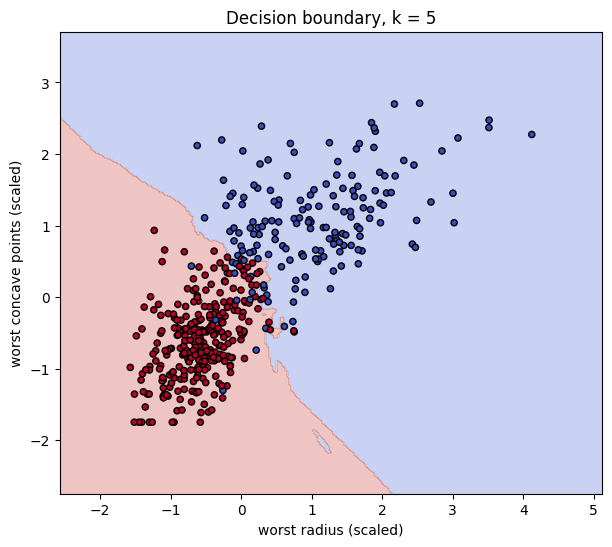

In [ ]:
# ---------- 1. Train KNN on the 2 features ----------

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X2_train_scaled, y_train)

# ---------- 2. Find the edges of the map ----------

# Left and right edges: smallest and biggest x, with a margin of 1
x_min = X2_train_scaled[:, 0].min() - 1
x_max = X2_train_scaled[:, 0].max() + 1

# Bottom and top edges: smallest and biggest y, with a margin of 1
y_min = X2_train_scaled[:, 1].min() - 1
y_max = X2_train_scaled[:, 1].max() + 1

# ---------- 3. Create a grid of 300 x 300 points covering the map ----------

x_values = np.linspace(x_min, x_max, 300)   # 300 evenly spaced x values
y_values = np.linspace(y_min, y_max, 300)   # 300 evenly spaced y values

# Every (x, y) combination → 90,000 points
# xx = the x of each point, yy = the y of each point (both 300 x 300 tables)
xx, yy = np.meshgrid(x_values, y_values)

# Flatten both tables and put them side by side:
# 90,000 rows x 2 columns, the same shape as our patients table
grid = np.c_[xx.ravel(), yy.ravel()]

# ---------- 4. Predict every point of the grid ----------

predictions = knn.predict(grid)       # 90,000 answers (0 or 1), in one long list
Z = predictions.reshape(xx.shape)     # put them back into a 300 x 300 square

# ---------- 5. Draw ----------

plt.figure(figsize=(7, 6))

# Paint the background: blue where KNN says 0, red where KNN says 1
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")   # alpha = light colors

# Draw the real patients on top
plt.scatter(
    X2_train_scaled[:, 0], X2_train_scaled[:, 1],
    c=y_train, cmap="coolwarm", edgecolor="k", s=20
)

plt.xlabel(f1 + " (scaled)")
plt.ylabel(f2 + " (scaled)")
plt.title("Decision boundary, k = 5")
plt.show()

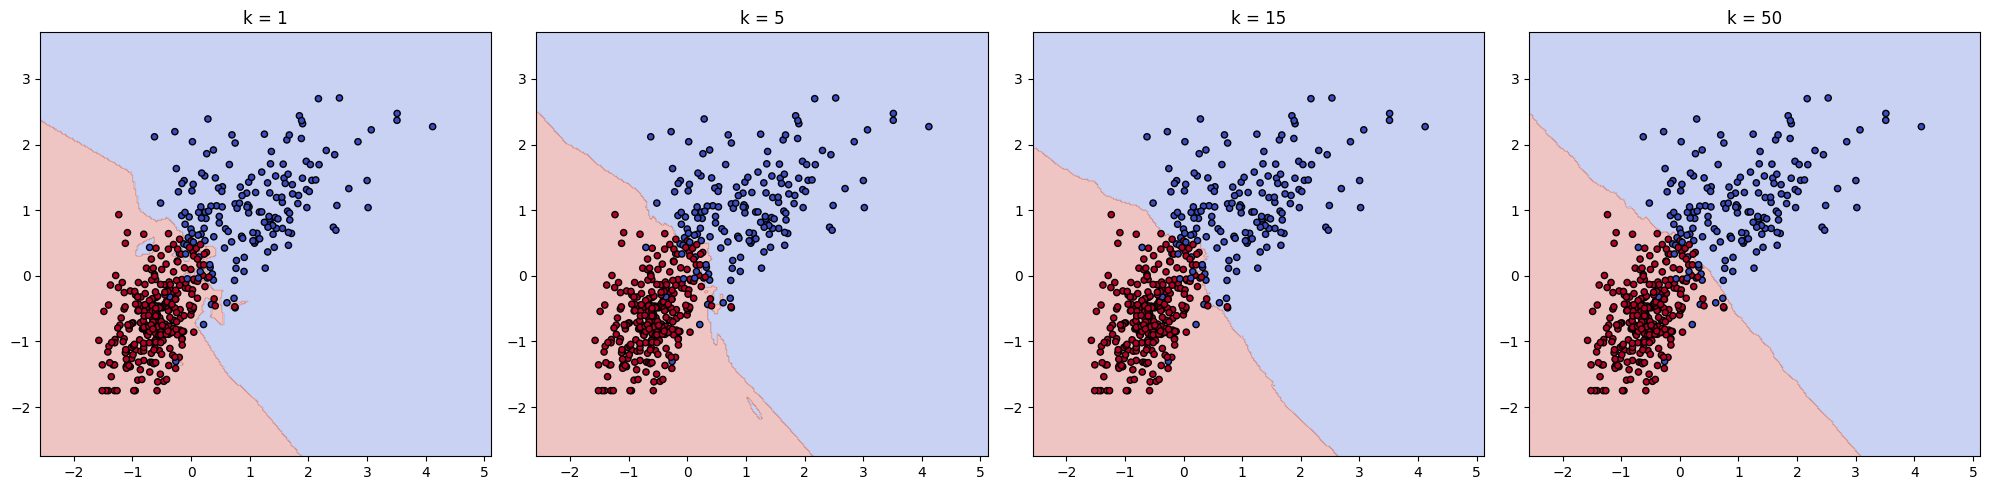

In [ ]:
# Cell 3: compare k = 1, 5, 15, 50

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, k in zip(axes, [1, 5, 15, 50]):

    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X2_train_scaled, y_train)

    Z = knn.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(
        X2_train_scaled[:, 0], X2_train_scaled[:, 1],
        c=y_train, cmap="coolwarm", edgecolor="k", s=20
    )
    ax.set_title(f"k = {k}")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# ---------- 1. The model: scaling + KNN ----------
# Each step has a name ("scaler" and "knn") so GridSearch knows where each setting goes
pipe = Pipeline([
    ("scaler", StandardScaler()),       # step 1: put all features on the same scale
    ("knn", KNeighborsClassifier())     # step 2: KNN (GridSearch will fill in its settings)
])

# ---------- 2. All the options to test ----------
# "knn__" = this setting belongs to the step named "knn"
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15],    # k: how many neighbors vote
    "knn__metric": ["euclidean", "manhattan"],   # how to measure distance: bird or walking
    "knn__weights": ["uniform", "distance"]      # how votes count: all equal or closer = bigger
}
# 6 x 2 x 2 = 24 combinations

# ---------- 3. Test every combination ----------
# Each combination is tested with 10-fold cross-validation, on all 569 patients and 30 features
grid_search = GridSearchCV(pipe, param_grid, cv=10)
grid_search.fit(X, y)    # 24 combinations x 10 rounds = 240 trainings (10-20 seconds)

# ---------- 4. Show the winner ----------
print("Best settings:", grid_search.best_params_)              # the winning combination
print("Best accuracy:", round(grid_search.best_score_, 4))     # its average accuracy

Best settings: {'knn__metric': 'manhattan', 'knn__n_neighbors': 3, 'knn__weights': 'uniform'}
Best accuracy: 0.9719


[[41  2]
 [ 2 69]]


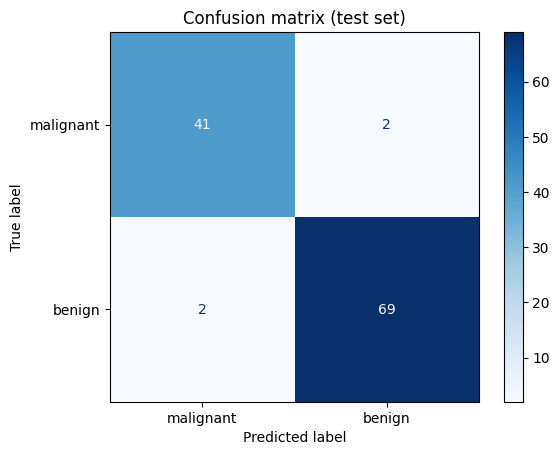

              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        43
      benign       0.97      0.97      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# ---------- 1. Take the best model from Part 6 and train it on the training set only ----------
model = grid_search.best_estimator_     # scaler + KNN with the best settings
model.fit(X_train, y_train)             # learn only from the 455 training patients

# ---------- 2. Predict the 114 test patients ----------
y_pred = model.predict(X_test)

# ---------- 3. Confusion matrix ----------
cm = confusion_matrix(y_test, y_pred)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=["malignant", "benign"]).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

# ---------- 4. Precision, recall, F1 for each class ----------
print(classification_report(y_test, y_pred, target_names=["malignant", "benign"]))